# CLIN diffusion model: re-evaluation on shared cases (land/sea, regions, ensemble, memorisation)

**Inputs** (all in `results/`):

| File | Produced by | Content |
|---|---|---|
| `eval_cases.csv` | `clin_common.py` | 240 cases: 60 per era, each a historical mask laid over a season-matched 1940s field |
| `diffusion_single.npz` | `run_diffusion_eval.py cases` | one reconstruction per case. Trained checkpoint `..._best_00236.pt`, same sampler as `target_period_sweep.py`: single-pass replacement inpainting, 1000 steps |
| `diffusion_ensemble.npz` | `run_diffusion_eval.py ensemble` | 8 reconstructions each for 10 cases per era |
| `diffusion_uncond.npz` | `run_diffusion_eval.py uncond` | 64 unconditional samples (dates from the 1950s) |
| `ridge_cases.npz` | `03_ridge_baseline.ipynb` | the regression baseline on the same cases, plus truth and climatology |

All errors are over the unobserved cells, in °C.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import clin_common as cc

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#898781", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": .6,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.titlesize": 10,
                     "axes.prop_cycle": plt.cycler(color=C)})
COL = {"climatology": "#898781", "ridge": C[0], "diffusion (1 sample)": C[1], "diffusion (ens. mean)": C[3]}

LAT, LON, ELEV, LSM = cc.load_static()
NLAT, NLON = len(LAT), len(LON)
LAND = (LSM > 0.5).ravel()
EXT = [LON[0], LON[-1], LAT[-1], LAT[0]]
H, HD, HDOLY, meta, cell = cc.load_hist(LAT, LON)
OBS = np.isfinite(H)

cases = pd.read_csv(cc.CASES_FILE)
R = np.load(cc.RESULTS_DIR / "ridge_cases.npz")
TRUTH = R["truth"].reshape(len(cases), -1); CLIM = R["clim"].reshape(len(cases), -1); RIDGE = R["pred"].reshape(len(cases), -1)
D1 = np.load(cc.RESULTS_DIR / "diffusion_single.npz")
done1 = D1["done"][:, 0]
DIFF = D1["recon"][:, 0].astype(np.float32).reshape(len(cases), -1)
KNOWN = np.zeros((len(cases), NLAT * NLON), bool)
for i, r in enumerate(cases.itertuples()):
    KNOWN[i, np.unique(cell[OBS[r.hist_row]])] = True
print(f"diffusion single samples available: {done1.sum()} / {len(cases)}")
assert np.allclose(DIFF[done1][KNOWN[done1]], TRUTH[done1][KNOWN[done1]], atol=0.05), "observed cells should equal truth"

diffusion single samples available: 240 / 240


## 1. Does the re-run reproduce STATUS?

STATUS §5 reports the sweep over all 99,710 days. Here we have 60 random days per era, so expect agreement within sampling noise (±0.1–0.2 °C).

In [2]:
LLAT, LLON = np.meshgrid(LAT, LON, indexing="ij"); LLAT, LLON = LLAT.ravel(), LLON.ravel()
rows = []
for i, r in enumerate(cases.itertuples()):
    if not done1[i]: continue
    known = KNOWN[i]
    dist = cc.haversine_min(LLAT, LLON, LLAT[known], LLON[known])
    for name, pred in [("climatology", CLIM[i]), ("ridge", RIDGE[i]), ("diffusion (1 sample)", DIFF[i])]:
        rec = {"case": i, "era": r.era, "n_obs": known.sum(), "method": name}
        rec.update(cc.score(pred, TRUTH[i], known, LAND))
        e2 = (pred - TRUTH[i]) ** 2
        for lo_, hi_ in [(0, 100), (100, 250), (250, 500), (500, 1e9)]:
            m = (dist >= lo_) & (dist < hi_) & ~known
            rec[f"{lo_}-{hi_ if hi_ < 1e9 else 'inf'} km"] = np.sqrt(e2[m].mean()) if m.any() else np.nan
        rows.append(rec)
S = pd.DataFrame(rows)
status = pd.Series([3.99, 3.98, 3.96, 3.83], index=[f"{a}-{b}" for a, b, _ in cc.ERAS])
rep = S[S.method == "diffusion (1 sample)"].groupby("era", sort=False).rmse_all.mean().to_frame("re-run (this notebook)")
rep["STATUS sweep"] = status
display(rep.round(2))

,re-run (this notebook),STATUS sweep
era,,
1667-1746,3.89,3.99
1747-1766,4.29,3.98
1767-1846,3.78,3.96
1847-1939,3.63,3.83


## 2. Land vs sea, and all methods side by side

In [3]:
# Ensemble mean (subset of cases) for a fair comparison with the deterministic ridge estimate
ens_path = cc.RESULTS_DIR / "diffusion_ensemble.npz"
HAVE_ENS = ens_path.exists()
if HAVE_ENS:
    E = np.load(ens_path)
    ens_case, ens_done = E["case"], E["done"]
    full = ens_done.all(1)
    ens_case = ens_case[full]
    ENS = E["recon"][full].astype(np.float32).reshape(full.sum(), E["recon"].shape[1], -1)
    rows = []
    for k, i in enumerate(ens_case):
        mean = ENS[k].mean(0)
        rec = {"case": i, "era": cases.era[i], "n_obs": KNOWN[i].sum(), "method": "diffusion (ens. mean)"}
        rec.update(cc.score(mean, TRUTH[i], KNOWN[i], LAND))
        rows.append(rec)
    S_ens = pd.DataFrame(rows)
    print(f"ensemble: {len(ens_case)} complete cases x {ENS.shape[1]} members")
else:
    S_ens = pd.DataFrame(); print("no ensemble results yet")

tab = pd.concat([S, S_ens]).pivot_table(index="era", columns="method", values=["rmse_all", "rmse_land", "rmse_sea"], sort=False)
display(tab.round(2))
if HAVE_ENS:
    sub = S[S.case.isin(ens_case)].pivot_table(index="era", columns="method", values="rmse_all", sort=False)
    sub["diffusion (ens. mean)"] = S_ens.groupby("era", sort=False).rmse_all.mean()
    print("Same subset of cases (the ensemble cases only), RMSE all cells:"); display(sub.round(2))

ensemble: 40 complete cases x 8 members


rmse_all                                                   \
method    climatology ridge diffusion (1 sample) diffusion (ens. mean)   
era                                                                      
1667-1746        2.66  2.24                 3.89                  2.84   
1747-1766        2.95  1.91                 4.29                  3.27   
1767-1846        2.84  1.63                 3.78                  3.61   
1847-1939        2.66  1.08                 3.63                  2.74   

            rmse_land                                                   \
method    climatology ridge diffusion (1 sample) diffusion (ens. mean)   
era                                                                      
1667-1746        3.23  2.68                 4.73                  3.50   
1747-1766        3.62  2.28                 5.27                  4.00   
1767-1846        3.49  1.88                 4.64                  4.51   
1847-1939        3.26  1.22                 4.46                  3.38   

             rmse_sea                                                   
method    climatology ridge diffusion (1 sample) diffusion (ens. mean)  
era                                                                     
1667-1746        1.66  1.50                 2.45                  1.63  
1747-1766        1.74  1.29                 2.55                  2.01  
1767-1846        1.69  1.21                 2.26                  1.95  
1847-1939        1.59  0.87                 2.17                  1.62

Same subset of cases (the ensemble cases only), RMSE all cells:


method,climatology,ridge,diffusion (1 sample),diffusion (ens. mean)
era,,,,
1667-1746,2.72,2.53,3.69,2.84
1747-1766,3.08,1.89,4.24,3.27
1767-1846,3.50,2.21,4.25,3.61
1847-1939,2.53,1.35,3.53,2.74


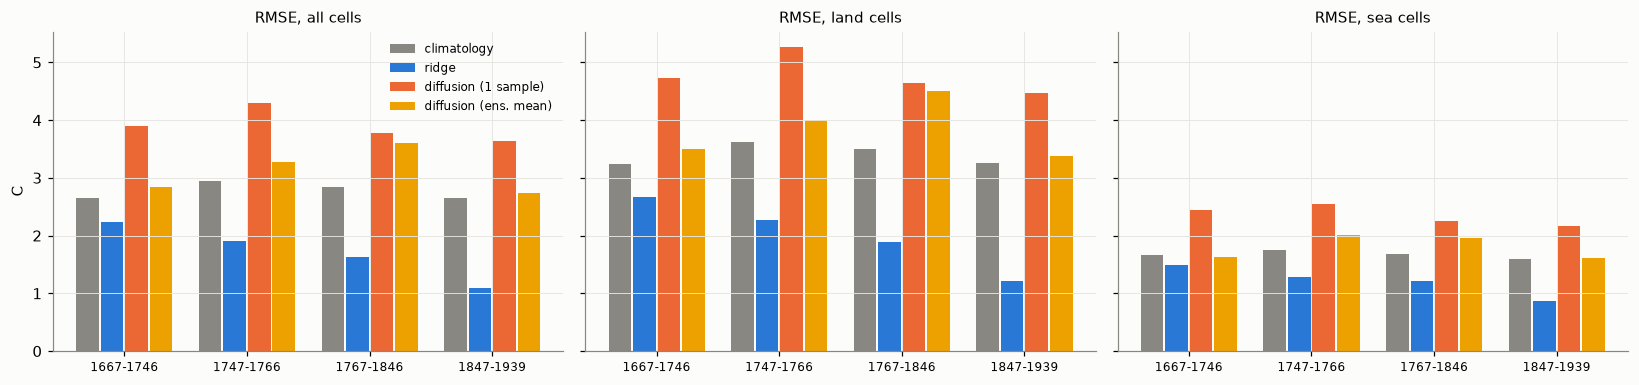

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
plot_df = pd.concat([S, S_ens])
eras = [e for e in (f"{a}-{b}" for a, b, _ in cc.ERAS) if e in set(plot_df.era)]
methods = [m for m in COL if m in plot_df.method.unique()]
w = 0.8 / len(methods)
for ax, part in zip(axs, ["all", "land", "sea"]):
    g = plot_df.groupby(["era", "method"])[f"rmse_{part}"].mean().unstack()
    for j, m in enumerate(methods):
        ax.bar(np.arange(len(eras)) + (j - (len(methods) - 1) / 2) * w, g.loc[eras, m], w * .92, color=COL[m], label=m)
    ax.set_xticks(range(len(eras)), eras, fontsize=8); ax.set_title(f"RMSE, {part} cells")
axs[0].set_ylabel("C"); axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

## 3. Does the diffusion model use the stations? Error by distance to the nearest observed cell

If the conditioning works, error should be much lower next to stations than far away, as it is for ridge.

,0-100 km,100-250 km,250-500 km,500-inf km
method,,,,
climatology,2.97,2.96,2.91,2.47
ridge,0.60,1.02,1.46,1.93
diffusion (1 sample),3.88,4.08,4.09,3.50


Text(0.5, 1.0, 'Error vs distance to a station (all eras)')

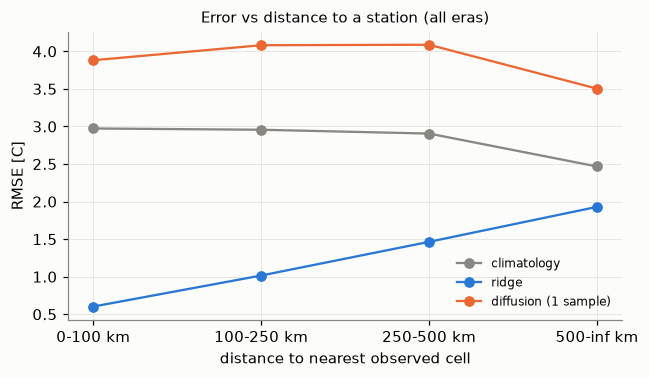

In [5]:
dcols = ["0-100 km", "100-250 km", "250-500 km", "500-inf km"]
dist_tab = S.groupby("method")[dcols].mean().loc[["climatology", "ridge", "diffusion (1 sample)"]]
display(dist_tab.round(2))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for m in dist_tab.index:
    ax.plot(range(4), dist_tab.loc[m], "o-", color=COL[m], label=m)
ax.set_xticks(range(4), dcols); ax.set_ylabel("RMSE [C]"); ax.set_xlabel("distance to nearest observed cell")
ax.legend(frameon=False, fontsize=8); ax.set_title("Error vs distance to a station (all eras)")

## 4. Where is the error? Per-cell RMSE maps and regions

These maps answer "which areas are bad" directly. The regions include the ones where the de-warmed ERA5 keeps a residual trend: northern Scandinavia, the southern Baltic/Denmark, and western Russia.

diffusion mean bias over unobserved cells: +0.37 C (land +0.46, sea +0.26)


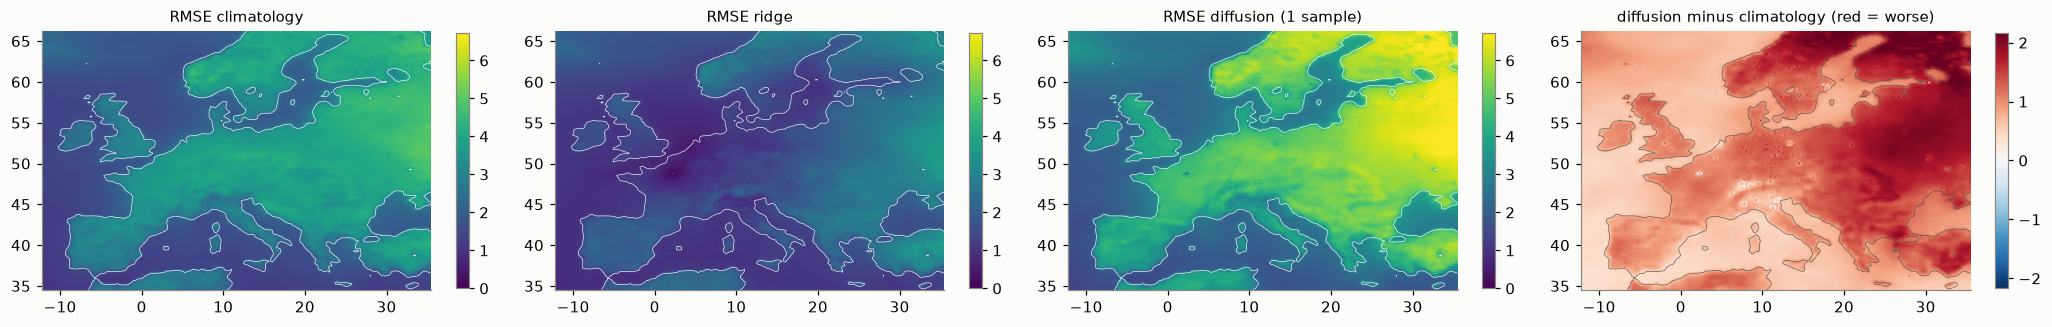

In [6]:
ok = np.where(done1)[0]
def cell_rmse(P):
    e2 = (P[ok] - TRUTH[ok]) ** 2
    e2[KNOWN[ok]] = np.nan
    with np.errstate(all="ignore"):
        return np.sqrt(np.nanmean(e2, 0))
maps = {"climatology": cell_rmse(CLIM), "ridge": cell_rmse(RIDGE), "diffusion (1 sample)": cell_rmse(DIFF)}
vmax = np.nanpercentile(maps["diffusion (1 sample)"], 99)
fig, axs = plt.subplots(1, 4, figsize=(19, 3.4))
for ax, (name, m) in zip(axs, maps.items()):
    im = ax.imshow(m.reshape(NLAT, NLON), extent=EXT, cmap="viridis", vmin=0, vmax=vmax)
    ax.contour(LON, LAT, LSM, [0.5], colors="w", linewidths=.4); ax.set_title(f"RMSE {name}"); ax.grid(False)
    plt.colorbar(im, ax=ax, shrink=.75)
dd = (maps["diffusion (1 sample)"] - maps["climatology"]).reshape(NLAT, NLON); lim = np.nanpercentile(np.abs(dd), 99)
im = axs[3].imshow(dd, extent=EXT, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim)); axs[3].grid(False)
axs[3].contour(LON, LAT, LSM, [0.5], colors="#52514e", linewidths=.4); axs[3].set_title("diffusion minus climatology (red = worse)")
plt.colorbar(im, ax=axs[3], shrink=.75); plt.tight_layout()

# Mean error (bias) of the diffusion reconstructions: is the generated climate shifted?
bias = np.nanmean(np.where(KNOWN[ok], np.nan, DIFF[ok] - TRUTH[ok]), 0)
print(f"diffusion mean bias over unobserved cells: {np.nanmean(bias):+.2f} C (land {np.nanmean(bias[LAND]):+.2f}, sea {np.nanmean(bias[~LAND]):+.2f})")

In [7]:
REGIONS = {  # lat_min, lat_max, lon_min, lon_max, surface
    "N Scandinavia (>=64N)": (64, 67, 5, 36, "land"),
    "S Baltic / Denmark": (53, 58, 8, 20, "all"),
    "W Russia / Belarus (>=28E, >=50N)": (50, 67, 28, 36, "land"),
    "Alps": (44.5, 48.5, 5, 16, "land"),
    "Iberia": (36, 44, -10, 3.5, "land"),
    "Central Europe": (47, 54, 5, 20, "land"),
    "Atlantic (sea)": (35, 67, -13, -5, "sea"),
    "Mediterranean (sea)": (35, 45, 0, 30, "sea"),
}
rows = []
for name, (la0, la1, lo0, lo1, surf) in REGIONS.items():
    m = (LLAT >= la0) & (LLAT <= la1) & (LLON >= lo0) & (LLON <= lo1)
    m &= LAND if surf == "land" else (~LAND if surf == "sea" else True)
    rows.append({"region": name, "cells": int(m.sum()),
                 **{k: float(np.sqrt(np.nanmean(v[m] ** 2))) for k, v in maps.items()},
                 "diffusion bias": float(np.nanmean(bias[m]))})
display(pd.DataFrame(rows).set_index("region").round(2))

,cells,climatology,ridge,diffusion (1 sample),diffusion bias
region,,,,,
N Scandinavia (>=64N),831,4.12,2.84,6.17,1.02
S Baltic / Denmark,1029,2.79,1.29,3.85,0.37
"W Russia / Belarus (>=28E, >=50N)",1929,4.48,2.93,6.43,1.05
Alps,722,3.48,1.46,4.42,-0.04
Iberia,1141,2.92,1.94,3.83,0.17
Central Europe,1718,3.82,1.42,5.07,0.04
Atlantic (sea),3090,1.56,1.28,2.20,0.19
Mediterranean (sea),2726,1.66,1.21,2.33,0.22


## 5. Ensemble: is the spread a usable uncertainty?

With 8 members per case, check two things:
- **(a)** How much does averaging members help? For a well-calibrated model, ensemble-mean MSE ≈ ½ of single-sample MSE.
- **(b)** Does the ensemble spread match the error of the ensemble mean? The spread/skill ratio ≈ 1 when calibrated; < 1 means overconfident.

,single_rmse,ensmean_rmse,spread,ridge_rmse,mse ratio ens/single,spread/skill
era,,,,,,
1667-1746,3.75,2.84,2.71,2.53,0.57,0.95
1747-1766,4.04,3.27,2.65,1.89,0.65,0.81
1767-1846,4.42,3.61,2.73,2.21,0.67,0.76
1847-1939,3.72,2.74,2.75,1.35,0.54,1.00


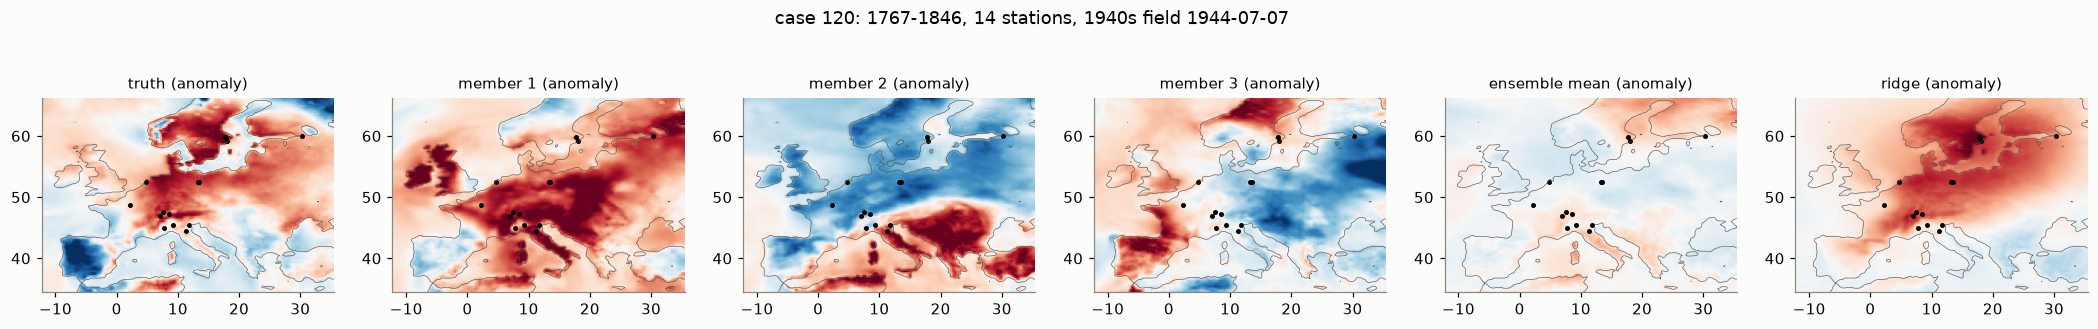

In [8]:
if HAVE_ENS:
    rows = []
    for k, i in enumerate(ens_case):
        un = ~KNOWN[i]
        mean = ENS[k].mean(0)
        single = np.mean([np.sqrt(np.mean((ENS[k][m] - TRUTH[i])[un] ** 2)) for m in range(ENS.shape[1])])
        rows.append({"era": cases.era[i], "single_rmse": single,
                     "ensmean_rmse": np.sqrt(np.mean((mean - TRUTH[i])[un] ** 2)),
                     "spread": np.sqrt(np.mean(ENS[k].var(0, ddof=1)[un])),
                     "ridge_rmse": np.sqrt(np.mean((RIDGE[i] - TRUTH[i])[un] ** 2))})
    ens_tab = pd.DataFrame(rows).groupby("era", sort=False).mean()
    ens_tab["mse ratio ens/single"] = (ens_tab.ensmean_rmse / ens_tab.single_rmse) ** 2
    ens_tab["spread/skill"] = ens_tab.spread / ens_tab.ensmean_rmse
    display(ens_tab.round(2))
    # Show one case: truth, 3 members, ensemble mean, ridge
    k = int(np.argmin(np.abs(ens_case - ens_case[len(ens_case) // 2]))); i = ens_case[k]
    fig, axs = plt.subplots(1, 6, figsize=(24, 3.2))
    anom = lambda f: (f - CLIM[i]).reshape(NLAT, NLON)
    lim = np.percentile(np.abs(anom(TRUTH[i])), 99)
    for ax, (title, f) in zip(axs, [("truth", TRUTH[i]), ("member 1", ENS[k][0]), ("member 2", ENS[k][1]), ("member 3", ENS[k][2]),
                                    ("ensemble mean", ENS[k].mean(0)), ("ridge", RIDGE[i])]):
        ax.imshow(anom(f), extent=EXT, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim)); ax.grid(False)
        ax.contour(LON, LAT, LSM, [0.5], colors="#52514e", linewidths=.4)
        kk = np.where(KNOWN[i])[0]; ax.scatter(LLON[kk], LLAT[kk], s=5, color="k"); ax.set_title(f"{title} (anomaly)")
    fig.suptitle(f"case {i}: {cases.era[i]}, {KNOWN[i].sum()} stations, 1940s field {cases.test_date[i]}", y=1.02)

## 6. The unconditional prior: realistic fields? Memorised fields?

- **Realism:** compare the mean and variance of the unconditional samples' anomalies with real ERA5 fields of the same dates.
- **Memorisation:** for every generated field, find its nearest training field (1960–2025) by RMSE. Do the same for the *real* 1950s fields of the same dates. If generated fields sit much closer to the training set than real unseen fields do, the model is reproducing training days.

anomaly mean: generated +0.58 C vs real -0.28 C
anomaly SD:   generated 2.77 C vs real 2.80 C (ratio 0.99)
land / sea SD ratio: 0.99 / 0.96


nearest-training-field RMSE: generated median 1.67 C (min 1.27) | real unseen 1950s median 1.70 C (min 1.31)


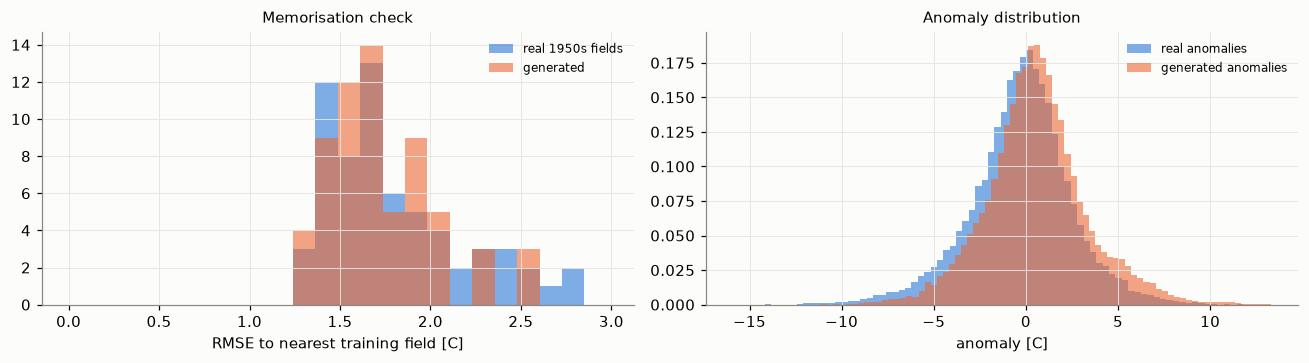

In [9]:
U = np.load(cc.RESULTS_DIR / "diffusion_uncond.npz")
samples = U["samples"].reshape(len(U["samples"]), -1).astype(np.float32)
udates = pd.to_datetime(U["dates"])
T, DATES, DOLY = cc.load_era5(1950, 2025)
flat = T.reshape(len(T), -1); del T
tr = DATES.year.values >= cc.TRAIN_YEARS[0]
Hm = cc.harmonics(DOLY)
COEF = np.linalg.lstsq(Hm[tr], flat[tr], rcond=None)[0]
pos = np.searchsorted(DATES, udates)
real = flat[pos]                                         # the real 1950s fields for the same dates
clim_u = cc.harmonics(cc.day_of_leap_year(udates)) @ COEF
a_gen, a_real = samples - clim_u, real - clim_u
print(f"anomaly mean: generated {a_gen.mean():+.2f} C vs real {a_real.mean():+.2f} C")
print(f"anomaly SD:   generated {a_gen.std():.2f} C vs real {a_real.std():.2f} C (ratio {a_gen.std()/a_real.std():.2f})")
print(f"land / sea SD ratio: {a_gen[:, LAND].std()/a_real[:, LAND].std():.2f} / {a_gen[:, ~LAND].std()/a_real[:, ~LAND].std():.2f}")

def nn_rmse(Q, Xtr, chunk=4000):
    q2 = (Q ** 2).sum(1)
    best = np.full(len(Q), np.inf); arg = np.zeros(len(Q), int)
    for s in range(0, len(Xtr), chunk):
        X = Xtr[s:s + chunk]
        d2 = q2[:, None] + (X ** 2).sum(1)[None] - 2 * Q @ X.T
        j = d2.argmin(1); v = d2[np.arange(len(Q)), j]
        upd = v < best; best[upd] = v[upd]; arg[upd] = s + j[upd]
    return np.sqrt(np.maximum(best, 0) / Q.shape[1]), arg

Xtr = flat[tr]
nn_gen, arg_gen = nn_rmse(samples, Xtr)
nn_real, _ = nn_rmse(real, Xtr)
print(f"nearest-training-field RMSE: generated median {np.median(nn_gen):.2f} C (min {nn_gen.min():.2f}) | "
      f"real unseen 1950s median {np.median(nn_real):.2f} C (min {nn_real.min():.2f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
bins = np.linspace(0, max(nn_gen.max(), nn_real.max()) * 1.05, 25)
ax[0].hist(nn_real, bins, color=C[0], alpha=.6, label="real 1950s fields"); ax[0].hist(nn_gen, bins, color=C[1], alpha=.6, label="generated")
ax[0].set_xlabel("RMSE to nearest training field [C]"); ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("Memorisation check")
ax[1].hist(a_real.ravel()[::50], 80, density=True, color=C[0], alpha=.6, label="real anomalies")
ax[1].hist(a_gen.ravel()[::50], 80, density=True, color=C[1], alpha=.6, label="generated anomalies")
ax[1].set_xlabel("anomaly [C]"); ax[1].legend(frameon=False, fontsize=8); ax[1].set_title("Anomaly distribution")
plt.tight_layout()

## 7. Summary (run of 2026-10-08)

**Reproduction.** The re-run matches the STATUS sweep within sampling noise. Single-sample RMSE by era is 3.89 / 4.29 / 3.78 / 3.63 °C here, vs 3.99 / 3.98 / 3.96 / 3.83 °C in STATUS.

**Land vs sea.** Land is about twice as bad as sea:

| Era | Land RMSE, diffusion 1 sample (°C) | Sea RMSE, diffusion 1 sample (°C) | Land RMSE, ridge (°C) | Sea RMSE, ridge (°C) |
|---|---|---|---|---|
| 1667–1746 | 4.73 | 2.45 | 2.68 | 1.50 |
| 1847–1939 | 4.46 | 2.17 | 1.22 | 0.87 |

**The stations are effectively ignored.** Three independent signs:
1. **Error doesn't depend on distance to a station.** The diffusion model scores 3.9 °C within 100 km and 3.5 °C beyond 500 km; ridge goes from 0.6 to 1.9 °C.
2. **The ensemble mean is no better than climatology** on the same cases (2.84 vs 2.72, 3.27 vs 3.08, 3.61 vs 3.50, 2.74 vs 2.53 °C by era).
3. **The ensemble spread is about 2.7 °C in every era.** It doesn't shrink from ~3 stations to ~170 stations. The members are draws from the unconditional prior; see the example in §5, where 14 stations report warm and one member is cold across the continent.

**The prior itself is good:**
- Unconditional samples have the right variability (anomaly SD ratio 0.99).
- Ensemble spread is roughly calibrated against the ensemble-mean error (spread/skill 0.76–1.0).
- **There's no sign of memorisation:** generated fields are no closer to their nearest training day (median 1.67 °C) than real unseen 1950s fields are (1.70 °C).

**Bias.** The generated fields run warm: +0.37 °C overall, about **+1.0 °C in northern Scandinavia and western Russia**. Those are the regions with residual de-warming trends and the most negatively skewed (cold-tailed) anomalies. Possible causes are under-produced cold tails or the residual trend; this hasn't been disentangled yet.

**Conclusion.** The trained network is a reasonable *unconditional* generator of de-warmed European temperature fields. What fails is the conditioning: single-pass replacement inpainting at 0.01–2% of the pixels doesn't propagate the station information. Hyperparameter tuning of the unconditional model won't fix that.

**Options, cheapest first:**
1. **Test RePaint resampling.** It's already implemented (`repaint_jump`, `repaint_resample`) and only costs sampling time. Check it on ~40 cases before anything else.
2. **Use guided / posterior sampling (DPS-style),** with a gradient of the station misfit at each step.
3. **Retrain conditionally:** station values and mask as input channels, optionally the ridge estimate as an extra channel, with training masks drawn from the real historical masks of all eras.

Every option should beat the ridge baseline (`03_ridge_baseline.ipynb`) on these same cases.
